# 01 · Análise exploratória dos leads

> ⚠️ **Dados 100% simulados.** A base foi gerada por `src/generate_data.py` (seed=42) apenas para fins de portfólio.

**Pergunta de negócio:** uma empresa de cursos online investe em Google Ads, Meta Ads, TikTok Ads, e-mail e orgânico.
Antes de construir um modelo, queremos entender:

1. A base está limpa o suficiente para modelar? (ausentes, duplicados, outliers)
2. Quão rara é a conversão?
3. Quais canais, criativos, dispositivos, regiões e idades convertem mais?
4. Quanto custa cada conversão em cada canal?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.plots import COLORS, conversion_by, plot_rate_bars, save_figure, set_style

set_style()
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv(ROOT / "data" / "raw" / "leads.csv", parse_dates=["data_cadastro"])
print(f"{df.shape[0]:,} leads e {df.shape[1]} colunas")
df.head()

50,000 leads e 15 colunas


,lead_id,data_cadastro,horario_cadastro,canal,campanha,criativo,dispositivo,uf,idade,paginas_vistas,tempo_no_site_seg,visitou_pagina_preco,abriu_email,custo_aquisicao_lead,converteu
0,L006302,2025-01-01,00:01,meta_ads,meta_prospeccao,video,NaN,BA,37.00,4,266.00,0,0,9.89,0
1,L006906,2025-01-01,00:13,meta_ads,meta_remarketing,video,mobile,SP,31.00,7,365.00,0,0,9.01,0
2,L045882,2025-01-01,00:24,google_ads,search_generico,video,mobile,MG,18.00,4,142.00,0,1,12.99,0
3,L037968,2025-01-01,00:40,meta_ads,meta_prospeccao,imagem_estatica,mobile,BA,43.00,4,29.00,1,1,15.68,0
4,L025588,2025-01-01,02:50,tiktok_ads,tiktok_awareness,video,mobile,BA,37.00,6,408.00,1,1,17.39,0


## 1. Qualidade dos dados

### 1.1 Valores ausentes e duplicados

In [2]:
ausentes = (
    df.isna().sum().to_frame("ausentes")
    .assign(percentual=lambda t: t["ausentes"] / len(df) * 100)
    .query("ausentes > 0")
    .sort_values("ausentes", ascending=False)
)
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"lead_id duplicados: {df['lead_id'].duplicated().sum()}")
ausentes

Linhas duplicadas: 0
lead_id duplicados: 0


,ausentes,percentual
dispositivo,1045,2.09
uf,1033,2.07
idade,1003,2.01
tempo_no_site_seg,981,1.96


**Conclusão:** não há duplicados, e quatro colunas têm cerca de 2% de valores ausentes (idade, tempo no site, dispositivo e UF).
O volume é pequeno, então vamos **imputar** em vez de descartar linhas: descartar perderia ~8% dos leads, e no mundo real
um lead com rastreamento falho continua sendo um lead que precisa de score.

### 1.2 Outliers no tempo de sessão

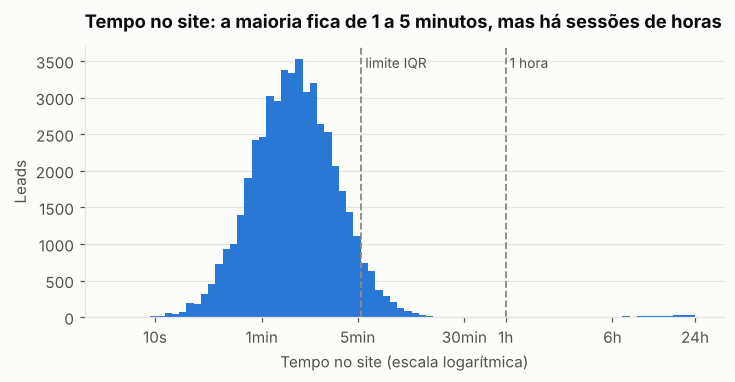

Acima do limite IQR (320s): 2,700 leads
Acima de 1 hora: 246 leads | máximo: 24.0 h


In [3]:
tempo = df["tempo_no_site_seg"].dropna()
q1, q3 = tempo.quantile([0.25, 0.75])
limite_iqr = q3 + 1.5 * (q3 - q1)
limite_negocio = 3_600  # 1 hora: acima disso a sessão quase certamente ficou esquecida aberta

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(np.log10(tempo), bins=80, color=COLORS["primary"])
for valor, rotulo in [(limite_iqr, "limite IQR"), (limite_negocio, "1 hora")]:
    ax.axvline(np.log10(valor), color=COLORS["reference"], linestyle="--", linewidth=1.2)
    ax.text(np.log10(valor), ax.get_ylim()[1] * 0.92, f" {rotulo}", color=COLORS["text_secondary"], fontsize=9)
ticks = [10, 60, 300, 1_800, 3_600, 21_600, 86_400]
ax.set_xticks(np.log10(ticks), ["10s", "1min", "5min", "30min", "1h", "6h", "24h"])
ax.set_title("Tempo no site: a maioria fica de 1 a 5 minutos, mas há sessões de horas")
ax.set_xlabel("Tempo no site (escala logarítmica)")
ax.set_ylabel("Leads")
ax.grid(axis="x", visible=False)
save_figure(fig, "01_outliers_tempo_no_site")
plt.show()

print(f"Acima do limite IQR ({limite_iqr:.0f}s): {(tempo > limite_iqr).sum():,} leads")
print(f"Acima de 1 hora: {(tempo > limite_negocio).sum():,} leads | máximo: {tempo.max() / 3600:.1f} h")

**Conclusão:** o tempo no site tem cauda longa natural (distribuição log-normal), por isso a regra do IQR marcaria ~2.700 leads
legítimos como outliers. Usamos um **critério de negócio**: sessões acima de 1 hora (~250 leads, 0,5%) são abas esquecidas
abertas ou bots. Na Etapa 3 esses valores serão **limitados (capping)**, e não removidos.

## 2. Distribuição do alvo

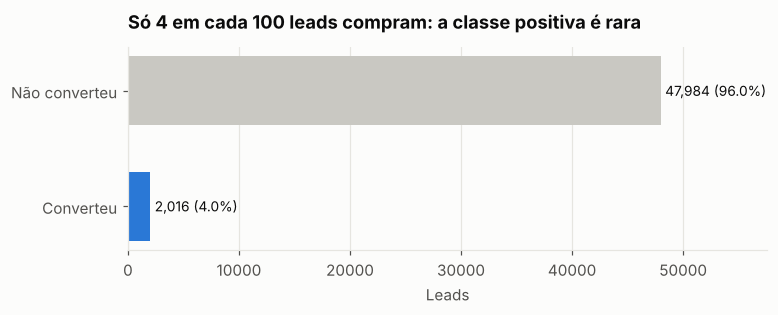

In [4]:
taxa_geral = df["converteu"].mean()
contagem = df["converteu"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7.5, 2.4))
ax.barh(["Converteu", "Não converteu"], [contagem[1], contagem[0]],
        color=[COLORS["primary"], COLORS["muted_bar"]], height=0.6)
for i, valor in enumerate([contagem[1], contagem[0]]):
    ax.text(valor + 400, i, f"{valor:,} ({valor / len(df):.1%})", va="center", fontsize=9)
ax.set_title("Só 4 em cada 100 leads compram: a classe positiva é rara")
ax.set_xlabel("Leads")
ax.set_xlim(0, contagem[0] * 1.2)
ax.grid(axis="y", visible=False)
save_figure(fig, "02_distribuicao_alvo")
plt.show()

**Conclusão:** a taxa de conversão é de **4,0%**, uma base fortemente desbalanceada. Um modelo que dissesse "ninguém compra" teria
96% de acurácia e nenhuma utilidade. Por isso, na modelagem, a métrica principal será a **PR-AUC**, e a divisão dos dados será estratificada.

## 3. Conversão por canal

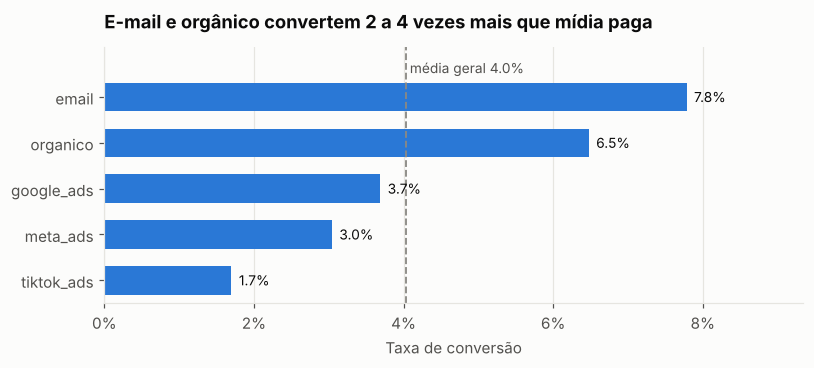

,leads,conversoes,taxa,ic95
canal,,,,
email,5101,397,0.08,0.01
google_ads,14940,551,0.04,0.00
meta_ads,14827,451,0.03,0.00
organico,7537,488,0.06,0.01
tiktok_ads,7595,129,0.02,0.00


In [5]:
por_canal = conversion_by(df, "canal")
fig = plot_rate_bars(por_canal, "E-mail e orgânico convertem 2 a 4 vezes mais que mídia paga", taxa_geral)
save_figure(fig, "03_conversao_por_canal")
plt.show()
por_canal

**Conclusão:** e-mail (7,8%) e orgânico (6,5%) convertem bem acima da média: são leads "quentes", que já conhecem a marca.
Entre os canais pagos, Google Ads (3,7%) lidera, e TikTok Ads (1,7%) fica bem abaixo, o que indica um público mais frio, de topo de funil.

## 4. Conversão por criativo

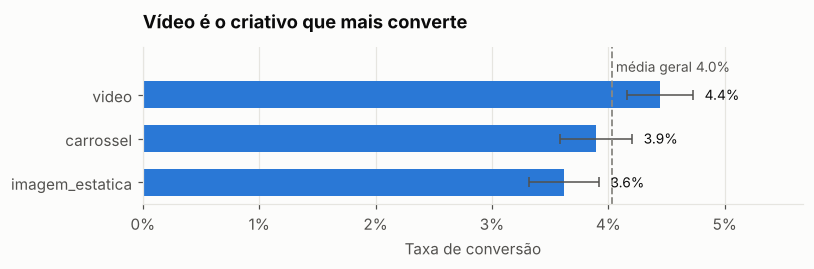

,leads,conversoes,taxa,ic95
criativo,,,,
carrossel,14972,583,0.04,0.00
imagem_estatica,14949,541,0.04,0.00
video,20079,892,0.04,0.00


In [6]:
por_criativo = conversion_by(df, "criativo")
fig = plot_rate_bars(por_criativo, "Vídeo é o criativo que mais converte", taxa_geral, show_ci=True)
save_figure(fig, "04_conversao_por_criativo")
plt.show()
por_criativo

**Conclusão:** vídeo converte 4,4%, contra 3,9% do carrossel e 3,6% da imagem estática. Os intervalos de confiança de vídeo e
imagem estática não se sobrepõem, então a diferença é real, mas pequena: o criativo pesa menos que o canal.

## 5. Conversão por dispositivo e horário

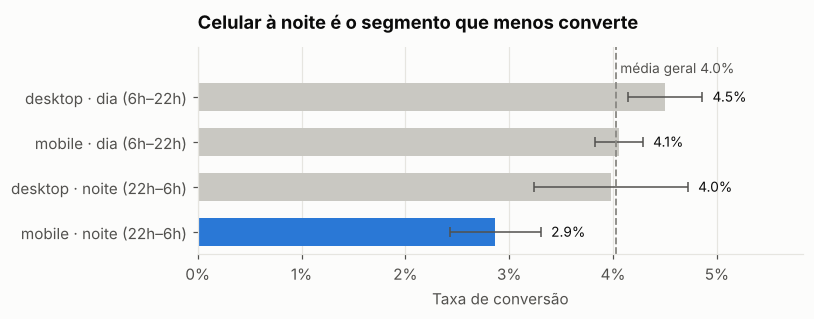

,leads,conversoes,taxa,ic95
segmento,,,,
desktop · dia (6h–22h),12932,582,0.05,0.00
desktop · noite (22h–6h),2665,106,0.04,0.01
mobile · dia (6h–22h),27775,1126,0.04,0.00
mobile · noite (22h–6h),5583,160,0.03,0.00


In [7]:
hora = df["horario_cadastro"].str[:2].astype(int)
df_disp = df.assign(
    segmento=np.where((hora >= 22) | (hora < 6), "noite (22h–6h)", "dia (6h–22h)"),
).dropna(subset=["dispositivo"])
df_disp["segmento"] = df_disp["dispositivo"] + " · " + df_disp["segmento"]

por_dispositivo = conversion_by(df_disp, "segmento")
fig = plot_rate_bars(por_dispositivo, "Celular à noite é o segmento que menos converte", taxa_geral,
                     show_ci=True, highlight=["mobile · noite (22h–6h)"])
save_figure(fig, "05_conversao_dispositivo_horario")
plt.show()
por_dispositivo

**Conclusão:** no geral, desktop converte um pouco mais que mobile (4,4% contra 3,9%), mas a maior diferença está no **celular à noite**,
com 2,9%: é o lead que se cadastra deitado no sofá, por impulso. Horário e dispositivo combinados explicam mais que cada um sozinho,
por isso vamos criar a feature `periodo_do_dia` na Etapa 3.

## 6. Conversão por UF

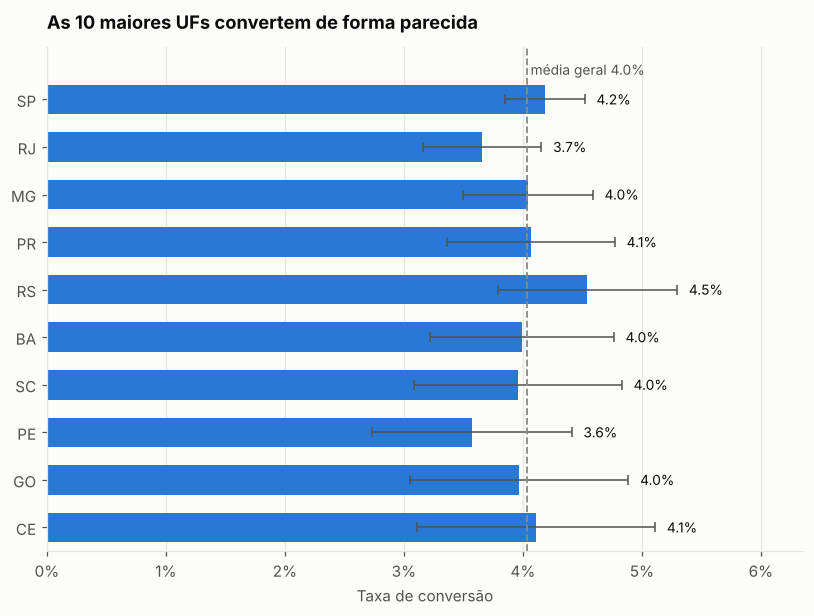

,leads,conversoes,taxa,ic95
uf,,,,
SP,13952,584,0.04,0.00
RJ,5495,201,0.04,0.00
MG,5046,204,0.04,0.01
PR,3001,122,0.04,0.01
RS,2929,133,0.05,0.01
BA,2480,99,0.04,0.01
SC,1920,76,0.04,0.01
PE,1877,67,0.04,0.01
GO,1739,69,0.04,0.01


In [8]:
por_uf = conversion_by(df, "uf").sort_values("leads", ascending=False).head(10)
fig = plot_rate_bars(por_uf, "As 10 maiores UFs convertem de forma parecida", taxa_geral,
                     sort=False, show_ci=True)
save_figure(fig, "06_conversao_por_uf")
plt.show()
por_uf

**Conclusão:** SP, RJ e MG concentram metade dos leads, mas as taxas das 10 maiores UFs variam de 3,6% a 4,5%, e todos os
intervalos de confiança cruzam a média geral. **A região não parece separar compradores de não compradores**: ela pode entrar no modelo,
mas não esperamos que pese muito. As UFs pequenas têm poucos leads, e suas taxas oscilam por puro acaso.

## 7. Conversão por faixa etária

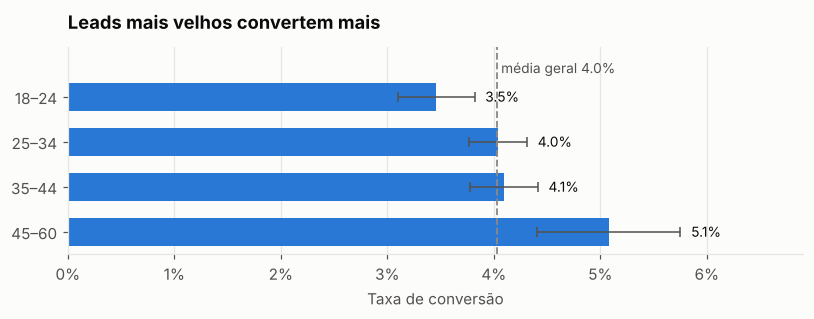

,leads,conversoes,taxa,ic95
faixa_etaria,,,,
18–24,9859,341,0.03,0.00
25–34,19978,807,0.04,0.00
35–44,15084,618,0.04,0.00
45–60,4076,207,0.05,0.01


In [9]:
df_idade = df.assign(faixa_etaria=pd.cut(df["idade"], bins=[17, 24, 34, 44, 60],
                                         labels=["18–24", "25–34", "35–44", "45–60"]))
por_idade = conversion_by(df_idade, "faixa_etaria")
fig = plot_rate_bars(por_idade, "Leads mais velhos convertem mais", taxa_geral, sort=False, show_ci=True)
save_figure(fig, "07_conversao_por_faixa_etaria")
plt.show()
por_idade

**Conclusão:** a conversão cresce com a idade, de 3,5% (18–24) a 5,1% (45–60). Uma hipótese de negócio é que o público mais velho
tem mais renda disponível e um objetivo profissional mais claro. A faixa de 45–60 é pequena (8% dos leads), mas é um nicho valioso.

## 8. Sinais de comportamento: página de preço e e-mail

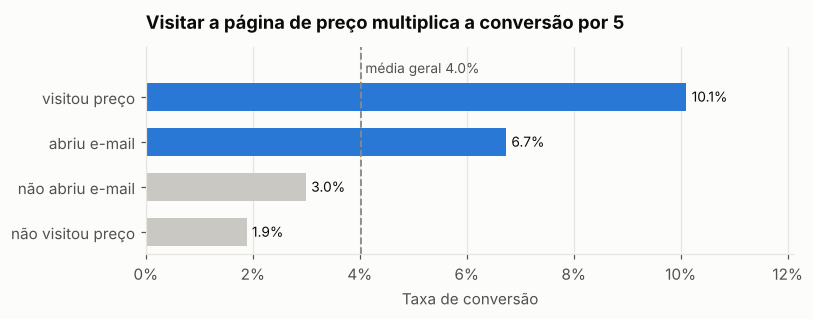

,leads,conversoes,taxa,ic95
não visitou preço,36938,696,0.02,0.00
visitou preço,13062,1320,0.10,0.01
não abriu e-mail,36117,1081,0.03,0.00
abriu e-mail,13883,935,0.07,0.00


In [10]:
sinais = pd.concat([
    conversion_by(df, "visitou_pagina_preco").rename(index={0: "não visitou preço", 1: "visitou preço"}),
    conversion_by(df, "abriu_email").rename(index={0: "não abriu e-mail", 1: "abriu e-mail"}),
])
fig = plot_rate_bars(sinais, "Visitar a página de preço multiplica a conversão por 5", taxa_geral,
                     highlight=["visitou preço", "abriu e-mail"])
save_figure(fig, "08_sinais_de_comportamento")
plt.show()
sinais

**Conclusão:** quem visitou a página de preço converte **10,1%**, contra 1,9% de quem não visitou: é o sinal individual mais forte da base.
Abrir e-mail dobra a chance (6,7% contra 3,0%). Comportamento pesa mais que perfil, o que é um bom sinal para um modelo de propensão.

## 9. Custo por conversão (CPA) por canal

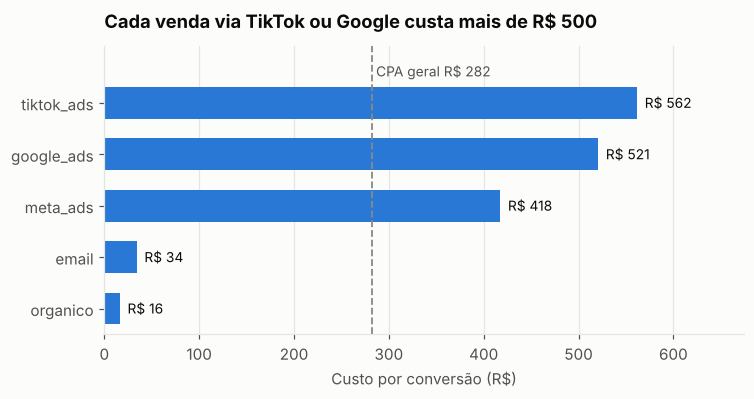

,leads,conversoes,investimento,cpl,cpa
canal,,,,,
organico,7537,488,"8,022.59",1.06,16.44
email,5101,397,"13,583.48",2.66,34.22
meta_ads,14827,451,"188,332.47",12.70,417.59
google_ads,14940,551,"286,958.93",19.21,520.80
tiktok_ads,7595,129,"72,474.28",9.54,561.82


In [11]:
custo = (
    df.groupby("canal")
    .agg(leads=("lead_id", "size"), conversoes=("converteu", "sum"), investimento=("custo_aquisicao_lead", "sum"))
    .assign(cpl=lambda t: t["investimento"] / t["leads"], cpa=lambda t: t["investimento"] / t["conversoes"])
    .sort_values("cpa")
)
cpa_geral = custo["investimento"].sum() / custo["conversoes"].sum()

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(custo.index, custo["cpa"], color=COLORS["primary"], height=0.62)
ax.axvline(cpa_geral, color=COLORS["reference"], linestyle="--", linewidth=1.2)
ax.set_ylim(-0.5, len(custo) + 0.1)
ax.text(cpa_geral, len(custo) - 0.55, f" CPA geral R$ {cpa_geral:,.0f}", color=COLORS["text_secondary"], fontsize=9, va="bottom")
for i, valor in enumerate(custo["cpa"]):
    ax.text(valor + 8, i, f"R$ {valor:,.0f}", va="center", fontsize=9)
ax.set_title("Cada venda via TikTok ou Google custa mais de R$ 500")
ax.set_xlabel("Custo por conversão (R$)")
ax.set_xlim(0, custo["cpa"].max() * 1.2)
ax.grid(axis="y", visible=False)
save_figure(fig, "09_cpa_por_canal")
plt.show()
custo

**Conclusão:** o CPA geral é de **R$ 282**, mas varia mais de 30 vezes entre canais: orgânico (R$ 16) e e-mail (R$ 34) são
quase de graça, enquanto Meta (R$ 418), Google (R$ 521) e TikTok (R$ 562) concentram **96% do investimento**. É na mídia paga que um
modelo de propensão tem mais espaço para reduzir o CPA, priorizando os leads com maior chance de compra.

## Resumo da análise

| Pergunta | Resposta |
|---|---|
| A base está pronta? | Quase: ~2% de ausentes em 4 colunas (imputar) e 0,5% de sessões acima de 1h (capping). Sem duplicados. |
| Quão rara é a compra? | 4,0%: classe desbalanceada → PR-AUC como métrica principal e divisão estratificada. |
| O que mais diferencia compradores? | Comportamento (página de preço, e-mail aberto) > canal > idade e horário > criativo. UF quase não diferencia. |
| Onde está o dinheiro? | Mídia paga concentra 96% do investimento, com CPA acima de R$ 400. |

**Próximo passo (Etapa 3):** transformar estes achados em features (`faixa_etaria`, `periodo_do_dia`, `dia_da_semana`, `engajamento`)
e montar um pipeline de pré-processamento sem vazamento de dados.